In [62]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pandas_datareader import data as web

# Download S&P 500 data from FRED
start_date = "2017-09-01"
end_date = "2026-08-31"

sp500 = web.DataReader("SP500", "fred", start_date, end_date)

# Convert daily data to monthly data
monthly_sp500 = sp500.resample("M").last()

# Keep the last 100 month-end observations
monthly_sp500 = monthly_sp500.tail(108)

# Calculate monthly simple returns
monthly_sp500["Return"] = monthly_sp500["SP500"].pct_change()

display(monthly_sp500)


,SP500,Return
DATE,,
2017-09-30,2519.36,NaN
2017-10-31,2575.26,0.022188
2017-11-30,2647.58,0.028083
2017-12-31,2673.61,0.009832
2018-01-31,2823.81,0.056179
...,...,...
2026-04-30,7209.01,0.104233
2026-05-31,7580.06,0.051470
2026-06-30,7499.36,-0.010646


In [63]:
#1a

# Remove the first NaN return
returns = monthly_sp500["Return"].dropna()

# Estimate mu and sigma
mu_hat = returns.mean()
sigma_hat = returns.std()

print("Estimated mu:", mu_hat)
print("Estimated sigma:", sigma_hat)

from scipy import stats
t_stat, p_value = stats.ttest_1samp(returns, 0)

alpha = 0.05

print("t = ", t_stat)
print("p = ", p_value)

if p_value < alpha:
    print("Reject H0: μ is significantly different from zero at 5%")
else:
    print("Do not reject H0: μ is not significantly different from zero at 5%")

Estimated mu: 0.011561416313324066
Estimated sigma: 0.04665167696027063
t =  2.5635138553288273
p =  0.011764036366716508
Reject H0: μ is significantly different from zero at 5%


In [64]:
#1c

from scipy.stats import jarque_bera

stat, p_value = jarque_bera(returns)

print("Jarque-Bera statistic:", stat)
print("p-value:", p_value)

if p_value < 0.05:
    print("Reject H0: returns are not normally distributed at 5%.")
else:
    print("Do not reject H0: returns are consistent with a normal distribution at 5%.")

Jarque-Bera statistic: 3.3795406461147164
p-value: 0.18456190874033096
Do not reject H0: returns are consistent with a normal distribution at 5%.


In [65]:
#1d

# Calculate monthly log returns
log_returns = np.log(
    monthly_sp500["SP500"] / monthly_sp500["SP500"].shift(1)
).dropna()

# Estimate tilde sigma
sigma_tilde = log_returns.std()

# Estimate tilde mu
mu_tilde = log_returns.mean() + 0.5 * sigma_tilde**2

print("Estimated tilde mu:", mu_tilde)
print("Estimated tilde sigma:", sigma_tilde)

Estimated tilde mu: 0.011514577002506368
Estimated tilde sigma: 0.04669365931241486


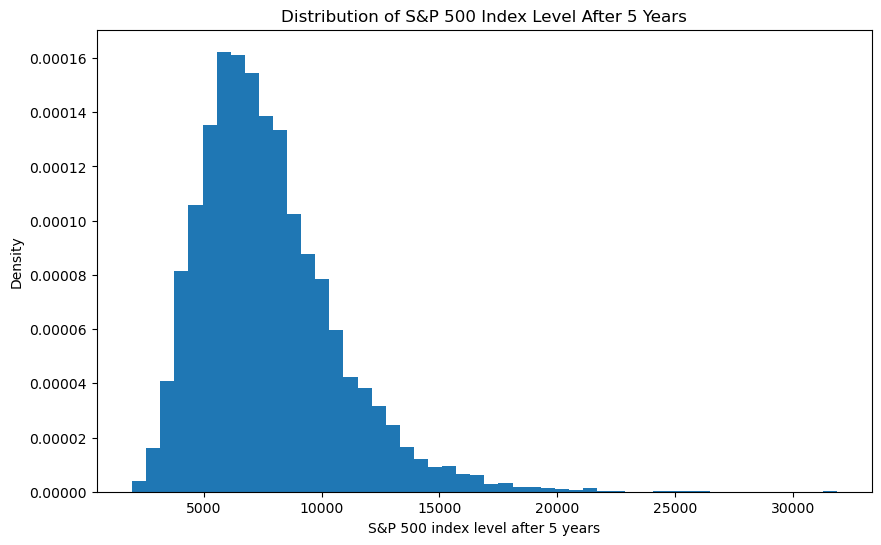

In [66]:
#1e

# Number of simulations and time horizon
n_simulations = 10000
n_months = 60

# Starting S&P 500 level
S0 = monthly_sp500["SP500"].iloc[-1]

# Use the same random number generator as in the first code
rng = np.random.default_rng(12345)
epsilon = rng.standard_normal((n_simulations, n_months))

# Simulate the S&P 500 paths under Q
S = np.zeros((n_simulations, n_months + 1))
S[:, 0] = S0

for t in range(n_months):
    S[:, t+1] = S[:, t] * np.exp(
        -0.5 * sigma_tilde**2
        + sigma_tilde * epsilon[:, t]
    )

# Take the index level after 60 months
S_final = S[:, -1]

# Plot the distribution
plt.figure(figsize=(10, 6))
plt.hist(S_final, bins=50, density=True)
plt.xlabel("S&P 500 index level after 5 years")
plt.ylabel("Density")
plt.title("Distribution of S&P 500 Index Level After 5 Years")
plt.show()

In [67]:
#1f

rng = np.random.default_rng(12345)
z = rng.standard_normal((10_000, 60))
ST_Q = S0 * np.exp(np.cumsum(-sigma_tilde**2 / 2
                             + sigma_tilde * z, axis=1)[:, -1])
digital = np.sum(ST_Q < 7500)  
print(digital)

5353


## 2 Binomial Trees

In [68]:
#2a

p, target_mean = .55, .005

u = 1 + target_mean + sigma_hat * np.sqrt((1 - p) / p)
d = 1 + target_mean - sigma_hat * np.sqrt(p / (1 - p))

stock = [S0 * u ** np.arange(i + 1) * d ** (i - np.arange(i + 1))
         for i in range(4)]

tree_mean = p * (u - 1) + (1 - p) * (d - 1)
tree_var = p * (u - 1 - tree_mean)**2 + (1 - p) * (d - 1 - tree_mean)**2

print("u =", u)
print("d =", d)
print("mean =", tree_mean)
print("variance =", tree_var)

for i, row in enumerate(stock):
    print("Stock t=", i, ":", np.round(row, 2))

u = 1.047198029541296
d = 0.9534246305606381
mean = 0.004999999999999904
variance = 0.0021763789632054465
Stock t= 0 : [7686.14]
Stock t= 1 : [7328.16 8048.91]
Stock t= 2 : [6986.84 7674.03 8428.8 ]
Stock t= 3 : [6661.43 7316.61 8036.23 8826.63]


In [69]:
#2b

K, gross_3m = 7750, 1.0075
gross_month = gross_3m ** (1 / 3)

q = (gross_month - d) / (u - d)

call = [None] * 4
call[3] = np.maximum(stock[3] - K, 0)

for i in range(2, -1, -1):
    call[i] = ((1 - q) * call[i + 1][:-1]
               + q * call[i + 1][1:]) / gross_month

C0 = call[0][0]

print("q =", q)
print("Call price =", C0)

for i, row in enumerate(call):
    print("Call t=", i, ":", np.round(row, 2))

q = 0.5232736136785819
Call price = 264.3651914263185
Call t= 0 : [264.37]
Call t= 1 : [ 77.98 435.43]
Call t= 2 : [  0.   149.4  698.08]
Call t= 3 : [   0.      0.    286.23 1076.63]


In [70]:
#2c

T = .25
vol_year = sigma_hat * np.sqrt(12)
r_year = np.log(gross_3m) / T

d1 = (np.log(S0 / K) + (r_year + vol_year**2 / 2) * T) / (vol_year * np.sqrt(T))
d2 = d1 - vol_year * np.sqrt(T)

BS = S0 * stats.norm.cdf(d1) - K * np.exp(-r_year * T) * stats.norm.cdf(d2)

print("Black-Scholes =", BS)
print("Tree minus BS =", C0 - BS)

Black-Scholes = 244.72893808137542
Tree minus BS = 19.6362533449431


In [71]:
#2d

hedges = []

for i in range(3):
    for j in range(i + 1):
        delta = ((call[i + 1][j + 1] - call[i + 1][j])
                 / (stock[i + 1][j + 1] - stock[i + 1][j]))

        b = (call[i + 1][j] - delta * stock[i + 1][j]) / gross_month
        b_zero = b - C0 * gross_month**i
        value = delta * stock[i][j] + b_zero

        assert np.isclose(value, call[i][j] - C0 * gross_month**i)

        for next_j in (j, j + 1):
            next_value = delta * stock[i + 1][next_j] + b_zero * gross_month
            assert np.isclose(
                next_value,
                call[i + 1][next_j] - C0 * gross_month**(i + 1)
            )

        hedges.append((i, j, delta, b_zero, value))

        print("Node", (i, j), 
              ": delta =", round(delta, 4),
              ", bank =", round(b_zero, 2),
              ", value =", round(value, 2))

Node (0, 0) : delta = 0.4959 , bank = -3811.77 , value = 0.0
Node (1, 0) : delta = 0.2174 , bank = -1780.28 , value = -187.04
Node (1, 1) : delta = 0.7269 , bank = -5680.71 , value = 170.4
Node (2, 0) : delta = 0.0 , bank = -265.69 , value = -265.69
Node (2, 1) : delta = 0.3977 , bank = -3168.63 , value = -116.28
Node (2, 2) : delta = 1.0 , bank = -7996.41 , value = 432.4


Terminal payoff - strategy: [266.34793 266.34793 266.34793 266.34793]
Constant: 266.3479303620159
n = 3 call price = 264.36519142631914
n = 6 call price = 246.21664731697558
n = 10 call price = 247.3311218067294
n = 100 call price = 246.51378283706012
n = 1000 call price = 245.94107768023878
n = 10000 call price = 245.96906896435547


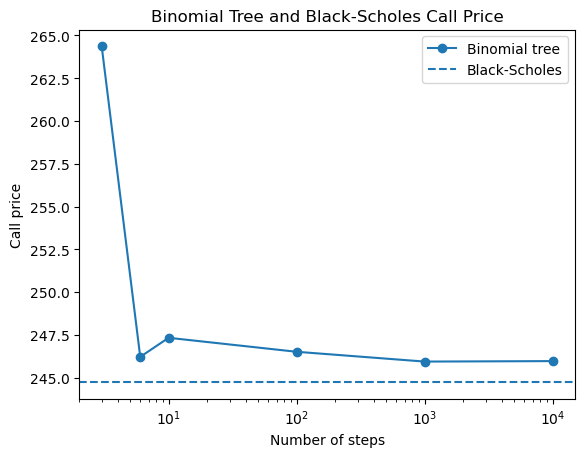

Black-Scholes price = 244.72893808137542


In [72]:
#2e

terminal_values = np.full(4, np.nan)

for i, j, delta, b_zero, value in hedges:
    if i == 2:
        for end_node in (j, j + 1):
            v = delta * stock[3][end_node] + b_zero * gross_month

            if np.isfinite(terminal_values[end_node]):
                assert np.isclose(terminal_values[end_node], v)

            terminal_values[end_node] = v

gap = call[3] - terminal_values

assert np.allclose(gap, C0 * gross_3m)

print("Terminal payoff - strategy:", np.round(gap, 6))
print("Constant:", C0 * gross_3m)


# 2(e)
steps = [3, 6, 10, 100, 1000, 10_000]
prices = []

for n in steps:
    scale = np.sqrt(3 / n)
    un = 1 + scale * (u - 1)
    dn = 1 + scale * (d - 1)

    gn = gross_3m ** (1 / n)
    qn = (gn - dn) / (un - dn)

    j = np.arange(n + 1)
    Sn = S0 * np.exp(j * np.log(un) + (n - j) * np.log(dn))

    V = np.maximum(Sn - K, 0)

    for _ in range(n):
        V = ((1 - qn) * V[:-1] + qn * V[1:]) / gn

    prices.append(V[0])

    print("n =", n, "call price =", V[0])


# Plot
plt.figure()

plt.semilogx(steps, prices, "o-", label="Binomial tree")
plt.axhline(BS, linestyle="--", label="Black-Scholes")

plt.title("Binomial Tree and Black-Scholes Call Price")
plt.xlabel("Number of steps")
plt.ylabel("Call price")

plt.legend()
plt.show()

print("Black-Scholes price =", BS)

## 3 Monte Carlo Simulation

In [73]:
#3a

import numpy as np
from scipy.stats import norm

# Given values
S0 = 7686.14
K = 7750
T = 3 / 12
sigma = 0.04669365931241486

# 3% annual interest rate with quarterly compounding
r = 4 * np.log(1 + 0.03 / 4)

# Binomial tree
N = 300
dt = T / N

u = np.exp(sigma * np.sqrt(dt))
d = np.exp(-sigma * np.sqrt(dt))

q = (np.exp(r * dt) - d) / (u - d)

# Stock prices at maturity
S = np.array([S0 * u**j * d**(N-j) for j in range(N + 1)])

# Call payoff at maturity
V = np.maximum(S - K, 0)

# Backward induction
for n in range(N, 0, -1):
    V = np.exp(-r * dt) * (q * V[1:n+1] + (1-q) * V[0:n])

call_binomial = V[0]

# Black-Scholes value
d1 = (np.log(S0 / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
d2 = d1 - sigma * np.sqrt(T)

call_bs = S0 * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)

# Results
print("Estimated sigma:", sigma)
print("Continuous interest rate:", r)
print("Binomial call price:", call_binomial)
print("Black-Scholes call price:", call_bs)
print("Difference:", call_binomial - call_bs)

Estimated sigma: 0.04669365931241486
Continuous interest rate: 0.029888059354804226
Binomial call price: 68.5324379208316
Black-Scholes call price: 68.57450759525045
Difference: -0.042069674418854675


In [74]:
#3b

# Given values
S0 = 7686.14
K = 7750
T = 3
dt = 1
sigma = 0.04669365931241486

# Continuously compounded monthly interest rate
r = 4 * np.log(1 + 0.03 / 4)

# Number of time steps
N = int(T / dt)

# Values of M
M_values = [100, 500, 1000, 5000, 10000]

# Set seed for reproducibility
rng = np.random.default_rng(12345)

for M in M_values:

    # Simulate M paths
    S = np.full(M, S0)

    for n in range(N):
        phi = rng.standard_normal(M)
        S = S + S * (r * dt / 12 + sigma * np.sqrt(dt / 12) * phi)

    # European call payoff
    payoff = np.maximum(S - K, 0)

    # Monte Carlo price
    price = np.exp(-r * T / 12) * np.mean(payoff)

    print(f"M = {M:5d}, Call price = {price:.4f}")

M =   100, Call price = 65.1466
M =   500, Call price = 73.0633
M =  1000, Call price = 67.6556
M =  5000, Call price = 71.1197
M = 10000, Call price = 68.9425


In [76]:
#3c

# Given values
S0 = 7686.14
K = 7750
T = 3 / 12
sigma = 0.04669365931241486

# Continuously compounded interest rate
r = 4 * np.log(1 + 0.03 / 4)

# 63 trading days per quarter
N = 63
dt = 1 / 252

# Values of M
M_values = [100, 500, 1000, 5000, 10000]

# Set seed for reproducibility
rng = np.random.default_rng(12345)

for M in M_values:

    # Start all simulations at S0
    S = np.full(M, S0)

    # Euler simulation
    for n in range(N):
        phi = rng.standard_normal(M)
        S = S + S * (r * dt + sigma * np.sqrt(dt) * phi)

    # European call payoff
    payoff = np.maximum(S - K, 0)

    # Discounted Monte Carlo price
    price = np.exp(-r * T) * np.mean(payoff)

    print(f"M = {M:5d}, Call price = {price:.4f}")

M =   100, Call price = 60.0641
M =   500, Call price = 73.7228
M =  1000, Call price = 71.2300
M =  5000, Call price = 69.6254
M = 10000, Call price = 70.2796


In [77]:
#3d

# Given values
S0 = 7686.14
K = 7750
T = 3 / 12
sigma = 0.04669365931241486

# Continuously compounded interest rate
r = 4 * np.log(1 + 0.03 / 4)

# 63 trading days per quarter
N = 63
dt = 1 / 252

# Values of M
M_values = [100, 500, 1000, 5000, 10000]

# Set seed for reproducibility
rng = np.random.default_rng(12345)

for M in M_values:

    # Start with log(S0)
    log_S = np.full(M, np.log(S0))

    # Euler simulation for log(S)
    for n in range(N):
        phi = rng.standard_normal(M)
        log_S = (log_S
                 + (r - 0.5 * sigma**2) * dt
                 + sigma * np.sqrt(dt) * phi)

    # Transform back from log(S) to S
    S = np.exp(log_S)

    # European call payoff
    payoff = np.maximum(S - K, 0)

    # Discounted Monte Carlo price
    price = np.exp(-r * T) * np.mean(payoff)

    print(f"M = {M:5d}, Call price = {price:.4f}")

M =   100, Call price = 60.0819
M =   500, Call price = 73.7307
M =  1000, Call price = 71.2440
M =  5000, Call price = 69.6341
M = 10000, Call price = 70.2888


In [78]:
#3e

# Given values
S0 = 7686.14
K = 7750
T = 3 / 12
sigma = 0.04669365931241486

# Continuously compounded interest rate
r = 4 * np.log(1 + 0.03 / 4)

# Values of M
M_values = [100, 500, 1000, 5000, 10000]

# Set seed for reproducibility
rng = np.random.default_rng(12345)

for M in M_values:

    # Mean and standard deviation of log(S_T)
    mean_log_ST = np.log(S0) + (r - 0.5 * sigma**2) * T
    std_log_ST = sigma * np.sqrt(T)

    # Directly simulate log(S_T)
    log_ST = rng.normal(mean_log_ST, std_log_ST, M)

    # Transform back to S_T
    ST = np.exp(log_ST)

    # European call payoff
    payoff = np.maximum(ST - K, 0)

    # Monte Carlo price
    price = np.exp(-r * T) * np.mean(payoff)

    print(f"M = {M:5d}, Call price = {price:.4f}")

M =   100, Call price = 63.2165
M =   500, Call price = 69.0937
M =  1000, Call price = 75.4613
M =  5000, Call price = 67.2301
M = 10000, Call price = 69.4616
